# Undulator scan aggregates — photon energy × GMD

Opens the energy-mode aggregates of an undulator scan and lays them out as plain arrays.

**Data.** By default run 60559 (`Ethanol_undulator_scan_2807989445`, nominal 265–282 eV), aggregated with
`analysis/configs/aggregates_run60559_energy.py`:

```
python analysis/scripts/photon_energy.py   <combined>.h5            # per-shot VLS photon energy -> photon_energy/
python analysis/scripts/compute_aggregates.py analysis/configs/aggregates_run60559_energy.py <combined>.h5
```

**Bins.** Measured photon energy (VLS peak centre per shot, calibrated against the nominal steps) in 0.5 eV bins ×
GMD in 5 bins at the 0/20/…/100th percentiles of the binned shots (GMD ≥ 0.02 µJ). Shots without a measured energy
(VLS signal below 5σ of the dark line) are not included. Bunch slots 0–99.

**Arrays** — means over the shots of each `(energy, GMD)` cell, NaN where a cell is empty:

| name | shape | |
|---|---|---|
| `D`, `C` | `(nE, nG, n_e)`, `(nE, nG, n_i)` | electron / ion spectrum, hits per shot per bin |
| `DtD`, `CtC`, `DtC` | `(nE, nG, n_e, n_e)`, … | second moments ⟨DDᵀ⟩, ⟨CCᵀ⟩, ⟨DCᵀ⟩ |
| `G`, `GtG`, `DtG`, `CtG` | `(nE, nG)`, … | ⟨G⟩, ⟨G²⟩, ⟨DG⟩, ⟨CG⟩ for partial covariance on GMD |
| `n` | `(nE, nG)` | shots per cell |
| `D_E`, `DtD_E`, `C_mq`, `CtC_mq`, `DtC_Emq`, … | same | the TOF arrays per eV / per u/e (calibrated axes `ke`, `mq`; section *Calibrated axes*) |

Covariance in a cell: `DtC − D[..., :, None] * C[..., None, :]`; with `var_G = GtG − G²` and
`cov_DG = DtG − D·G`, the partial covariance on GMD subtracts `cov_DG ⊗ cov_CG / var_G`. Merging cells: weight the
means by `n` before forming covariances.

In [1]:
# ---- Parameters ---------------------------------------------------------------
# AGG_H5 = "run60559_Ethanol_undulator_scan_2807989445_aggregates_energy.h5"   # relative to config.COMBINED_DIR or absolute
# AGG_H5 = "run60560_Ethanol_undulator_scan_2808016357_live_aggregates_energy.h5"
AGG_H5 = "run60560_Ethanol_undulator_scan_2808016357_aggregates_energy.h5"

In [2]:
# ---- Imports and paths ------------------------------------------------------
from pathlib import Path
import sys
import warnings

import h5py
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "analysis" / "scripts" / "config.py").exists())
sys.path.insert(0, str(REPO_ROOT / "analysis" / "scripts"))
import calibration
import config
from compute_aggregates import load_aggregates

warnings.filterwarnings("ignore", message="invalid value encountered")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
TDC_PER_NS = 10

## Load

In [3]:
agg_path = Path(AGG_H5)
agg_path = agg_path if agg_path.is_absolute() else config.COMBINED_DIR / agg_path
agg = load_aggregates(agg_path)
assert agg.mode == "energy", f"expected energy-mode aggregates, got {agg.mode!r}"

# Plain arrays
D, DtD, C, CtC, DtC = agg.D, agg.DtD, agg.C, agg.CtC, agg.DtC
G, GtG, DtG, CtG = agg.G, agg.GtG, agg.DtG, agg.CtG
n = agg.n_per_bin

# Axes
E_edges, E = agg.energy_edges, agg.energy_centres                 # eV
gmd_edges = agg.gmd_edges                                         # µJ (G holds the mean GMD of each cell)
tof_e_edges = agg.tof_edges / TDC_PER_NS                          # ns
tof_i_edges = agg.ion_tof_edges / TDC_PER_NS
tof_e = 0.5 * (tof_e_edges[1:] + tof_e_edges[:-1])
tof_i = 0.5 * (tof_i_edges[1:] + tof_i_edges[:-1])

meta = agg.metadata
print(f"{agg_path.name}")
print(f"  from {Path(meta['input_h5']).name}, config {meta.get('config_path', '-')}")
print(f"  {len(E)} energy bins {E_edges[0]:.2f}-{E_edges[-1]:.2f} eV ({meta.get('energy_key')}), "
      f"{len(gmd_edges) - 1} GMD bins {np.round(gmd_edges, 3).tolist()} µJ")
print(f"  electrons {len(tof_e)} bins {tof_e_edges[0]:.0f}-{tof_e_edges[-1]:.0f} ns, "
      f"ions {len(tof_i)} bins {tof_i_edges[0]:.0f}-{tof_i_edges[-1]:.0f} ns, bunch slots {meta.get('bunch_range')}")
print(f"  {n.sum()} shots binned; left out: {meta.get('n_skipped_energy_nan')} without a photon energy, "
      f"{meta.get('n_skipped_gmd_oor')} outside the GMD bins, {meta.get('n_skipped_max_hits')} over the hit caps")
for k in ("D", "DtD", "C", "CtC", "DtC", "G", "DtG", "CtG"):
    print(f"  {k:4s} {getattr(agg, k).shape}")

run60560_Ethanol_undulator_scan_2808016357_aggregates_energy.h5
  from run60560_Ethanol_undulator_scan_2808016357.h5, config analysis/configs/aggregates_run60560_energy.py
  39 energy bins 263.75-283.25 eV (photon_energy/measured), 5 GMD bins [0.02, 0.057, 0.1, 0.168, 0.29, 4.846] µJ
  electrons 252 bins 87-970 ns, ions 320 bins 200-3400 ns, bunch slots [0, 100]
  14712270 shots binned; left out: 2008533 without a photon energy, 2008502 outside the GMD bins, 41 over the hit caps
  D    (39, 5, 252)
  DtD  (39, 5, 252, 252)
  C    (39, 5, 320)
  CtC  (39, 5, 320, 320)
  DtC  (39, 5, 252, 320)
  G    (39, 5)
  DtG  (39, 5, 252)
  CtG  (39, 5, 320)


In [4]:
# Photon-energy calibration stored with the per-shot energies in the combined file
with h5py.File(meta["input_h5"] if Path(meta["input_h5"]).is_absolute()
               else REPO_ROOT / meta["input_h5"], "r") as f:
    pe = f["photon_energy"]
    cal_coef, cal_E, cal_px, cal_res = (pe[k][...] for k in ("cal_coef", "cal_energies", "cal_centres", "cal_residuals"))
print("E(pixel) = " + " + ".join(f"{c:.6g} px^{len(cal_coef) - 1 - i}" for i, c in enumerate(cal_coef)),
      f"| rms residual {np.sqrt(np.mean(cal_res ** 2)):.3f} eV over {len(cal_E)} nominal steps")

E(pixel) = -0.0590512 px^1 + 298.987 px^0 | rms residual 0.075 eV over 31 nominal steps


/tmp/ipykernel_2620396/1464230080.py:3: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  mesh = ax.pcolormesh(np.arange(len(gmd_edges)), E_edges, n, cmap="viridis")
/tmp/ipykernel_2620396/1464230080.py:4: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  fig.colorbar(mesh, ax=ax, label="shots")


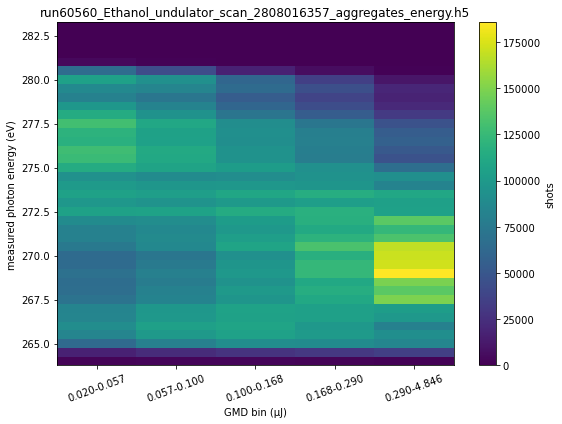

In [5]:
# Shots per cell
fig, ax = plt.subplots(figsize=(8, 6))
mesh = ax.pcolormesh(np.arange(len(gmd_edges)), E_edges, n, cmap="viridis")
fig.colorbar(mesh, ax=ax, label="shots")
ax.set_xticks(np.arange(len(gmd_edges) - 1) + 0.5,
              [f"{a:.3f}-{b:.3f}" for a, b in zip(gmd_edges[:-1], gmd_edges[1:])], rotation=20)
ax.set(xlabel="GMD bin (µJ)", ylabel="measured photon energy (eV)", title=agg_path.name)
ax.grid(False)
fig.tight_layout()
plt.show()

## Calibrated axes: electron energy and ion m/q

`analysis/scripts/calibration.py` (argon run 60538): $E_\mathrm{kin} = (a/(t-t_0))^2 + E_0$ for the electrons,
$m/q = ((t-t_0)/k)^2$ for the ions. Each TOF bin becomes the interval between the images of its edges; dividing by
its width (the Jacobian integrated over the bin) turns hits per bin into hits per eV (per u/e). Second moments and
covariances are divided by the widths of both axes, and covariances formed from the converted arrays are the converted
covariances. The arrays keep the TOF order: along the electron axis the energy falls.

The aggregates were binned in 5 ns electron TOF bins, which at the fast end are tens of eV wide (printed below); to
resolve the fast electrons in energy, aggregate on TOF edges that are images of energy edges (`TOF_EDGES =
10 * calibration.tof_of_ke(ke_edges)[::-1]`).

In [6]:
ke_edges, mq_edges = calibration.ke_of_tof(tof_e_edges), calibration.mq_of_tof(tof_i_edges)
ke, mq = calibration.ke_of_tof(tof_e), calibration.mq_of_tof(tof_i)       # bin centres (TOF order)
dke, dmq = np.abs(np.diff(ke_edges)), np.diff(mq_edges)                   # eV, u/e per bin
per = calibration.per_unit
D_E, DtD_E, DtG_E = per(D, dke), per(DtD, dke, dke), per(DtG, dke)
C_mq, CtC_mq, CtG_mq = per(C, dmq), per(CtC, dmq, dmq), per(CtG, dmq)
DtC_Emq = per(DtC, dke, dmq)
A, AtA, AtD, AtC, AtG = agg.A, agg.AtA, agg.AtD, agg.AtC, agg.AtG       # None without VLS
AtD_E = None if AtD is None else per(AtD, dke)
AtC_mq = None if AtC is None else per(AtC, dmq)

print("electron bins: " + ", ".join(f"{e:.0f} eV -> {w:.2g} eV wide"
                                    for e, w in zip(ke, dke) if any(abs(e - x) < w / 2 for x in (10, 25, 100, 200, 260))))
print("ion bins: " + ", ".join(f"m/q {q:.1f} -> {w:.2g} wide" for q, w in zip(mq, dmq)
                              if any(abs(q - x) < w / 2 for x in (1, 15, 28, 46))))

electron bins: 260 eV -> 1.4 eV wide, 201 eV -> 1.4 eV wide, 102 eV -> 4.9 eV wide, 25 eV -> 1.2 eV wide, 10 eV -> 0.48 eV wide
ion bins: m/q 1.0 -> 0.042 wide, m/q 15.0 -> 0.16 wide, m/q 27.9 -> 0.22 wide, m/q 46.0 -> 0.28 wide


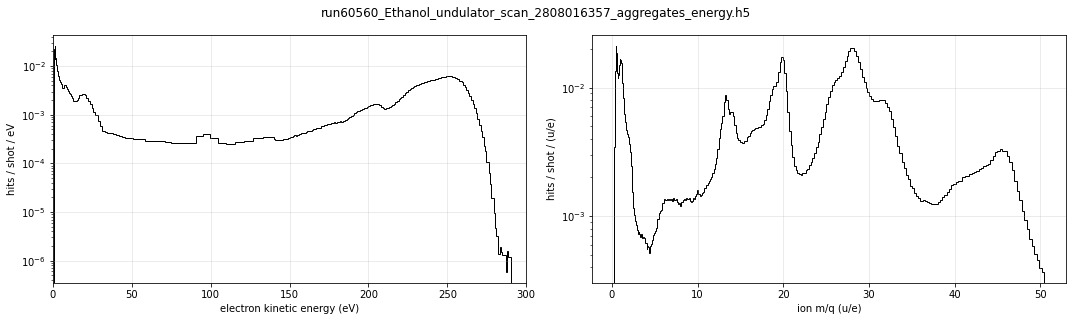

In [7]:
# All cells together (weighted by shots): electron and ion spectra on the calibrated axes
w = n[..., None] / n.sum()
D_all = np.nansum(np.nan_to_num(D_E) * w, axis=(0, 1))
C_all = np.nansum(np.nan_to_num(C_mq) * w, axis=(0, 1))
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
axs[0].stairs(D_all[::-1], ke_edges[::-1], color="k")
axs[0].set(xlabel="electron kinetic energy (eV)", ylabel="hits / shot / eV", yscale="log", xlim=(0, 300))
axs[1].stairs(C_all, mq_edges, color="k")
axs[1].set(xlabel="ion m/q (u/e)", ylabel="hits / shot / (u/e)", yscale="log")
fig.suptitle(agg_path.name)
fig.tight_layout()
plt.show()

## XAS maps: photon energy × electron kinetic energy, one per GMD bin

Each panel is one GMD bin. A row is one measured-photon-energy bin and the colour is the mean electron spectrum of
that cell on the calibrated kinetic-energy axis (`D_E`: hits / shot / eV, Jacobian included). With `XAS_NORM = "gmd"`
every cell is divided by its own mean GMD (hits / µJ / eV), so the panels compare directly: a response linear in
pulse energy looks the same in every panel. Cells with fewer than `XAS_MIN_SHOTS` shots are blank. Photolines run
along the diagonal (KE = hν − E_B), Auger lines are vertical (fixed KE).

In [8]:
# ---- XAS maps: parameters ------------------------------------------------------------
XAS_KE = (0, 290)            # electron kinetic-energy range shown (eV)
XAS_NORM = "gmd"             # "gmd": hits / µJ / eV (each cell / its mean GMD); "shot": hits / shot / eV
XAS_LOG = True               # log colour scale
XAS_SHARED_CLIM = True       # one colour scale for all GMD bins (False: one per panel)
XAS_MIN_SHOTS = 300          # cells with fewer shots are left blank

/tmp/ipykernel_2620396/1260006941.py:28: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  m = ax.pcolormesh(xas_edges, E_edges, np.ma.masked_invalid(xas_maps[:, j]), cmap="viridis",
/tmp/ipykernel_2620396/1260006941.py:39: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  fig.colorbar(m, ax=list(axs), label=xas_unit, pad=0.01)


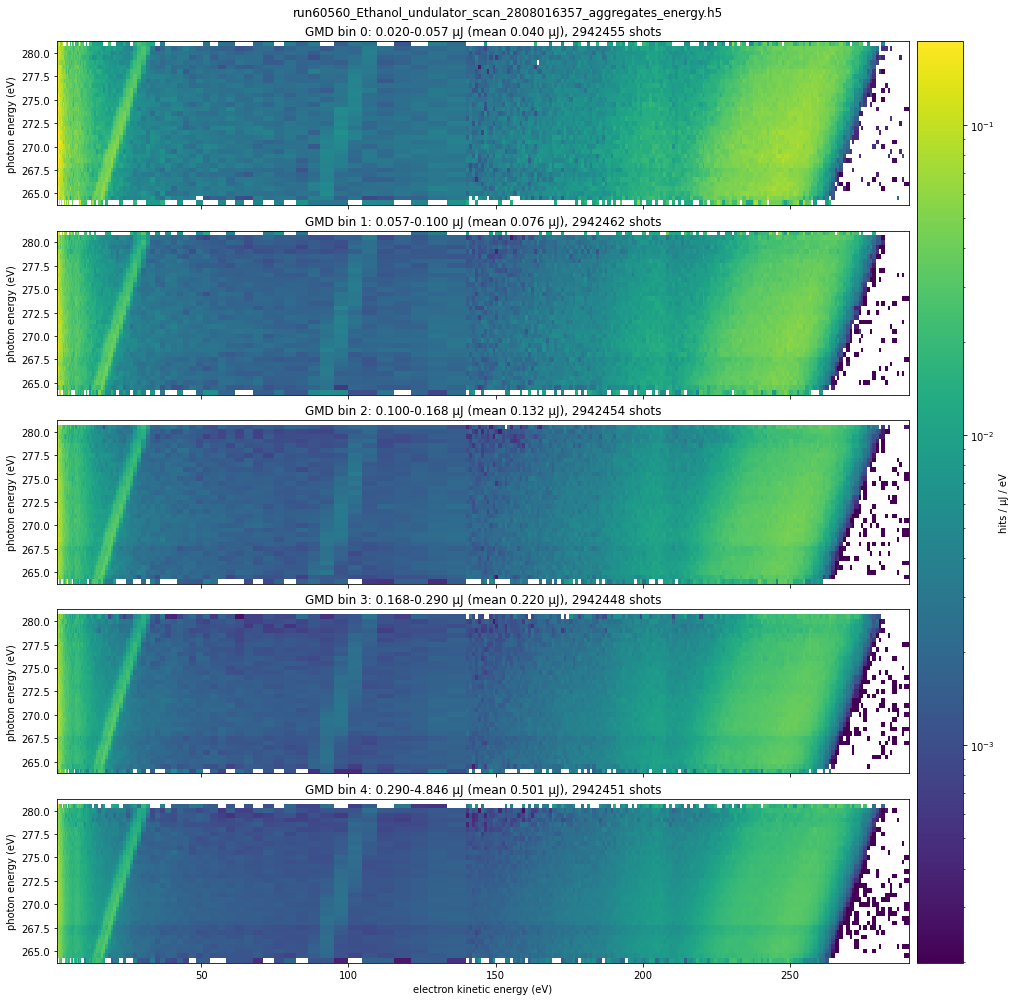

In [9]:
from matplotlib.colors import LogNorm, Normalize

# Per-eV spectra of every (photon energy, GMD) cell on rising kinetic energy (D_E is in TOF order = falling energy)
xas_edges, xas_maps = ke_edges[::-1], D_E[..., ::-1]
if XAS_NORM == "gmd":
    xas_maps = xas_maps / G[..., None]
xas_maps = np.where((n >= XAS_MIN_SHOTS)[..., None], xas_maps, np.nan)
xas_ke = 0.5 * (xas_edges[1:] + xas_edges[:-1])
cols = np.flatnonzero((xas_ke >= XAS_KE[0]) & (xas_ke <= XAS_KE[1]))
xas_maps, xas_edges = xas_maps[..., cols], xas_edges[cols[0]:cols[-1] + 2]
rows = np.flatnonzero(np.isfinite(xas_maps).any(axis=(1, 2)))            # photon-energy bins with data
xas_unit = "hits / µJ / eV" if XAS_NORM == "gmd" else "hits / shot / eV"


def xas_norm(a):
    v = a[np.isfinite(a) & (a > 0)] if XAS_LOG else a[np.isfinite(a)]
    if not v.size:
        return None
    lo, hi = np.percentile(v, [1, 99.5])
    return LogNorm(lo, hi) if XAS_LOG else Normalize(lo, hi)


n_g = xas_maps.shape[1]
fig, axs = plt.subplots(n_g, 1, figsize=(14, 2.6 * n_g + 0.8), sharex=True, squeeze=False, constrained_layout=True)
axs = axs[:, 0]
shared = xas_norm(xas_maps) if XAS_SHARED_CLIM else None
for j, ax in enumerate(axs):
    m = ax.pcolormesh(xas_edges, E_edges, np.ma.masked_invalid(xas_maps[:, j]), cmap="viridis",
                      norm=shared if XAS_SHARED_CLIM else xas_norm(xas_maps[:, j]))
    if not XAS_SHARED_CLIM:
        fig.colorbar(m, ax=ax, label=xas_unit, pad=0.01)
    g_mean = np.nansum(G[:, j] * n[:, j]) / max(n[:, j].sum(), 1)
    ax.set(ylabel="photon energy (eV)", ylim=(E_edges[rows[0]], E_edges[rows[-1] + 1]),
           title=f"GMD bin {j}: {gmd_edges[j]:.3f}-{gmd_edges[j + 1]:.3f} µJ (mean {g_mean:.3f} µJ), "
                 f"{n[:, j].sum()} shots")
    ax.grid(False)
axs[-1].set_xlabel("electron kinetic energy (eV)")
if XAS_SHARED_CLIM:
    fig.colorbar(m, ax=list(axs), label=xas_unit, pad=0.01)
fig.suptitle(agg_path.name)
plt.show()

In [10]:
D.shape

(39, 5, 252)

(0.0, 400.0)

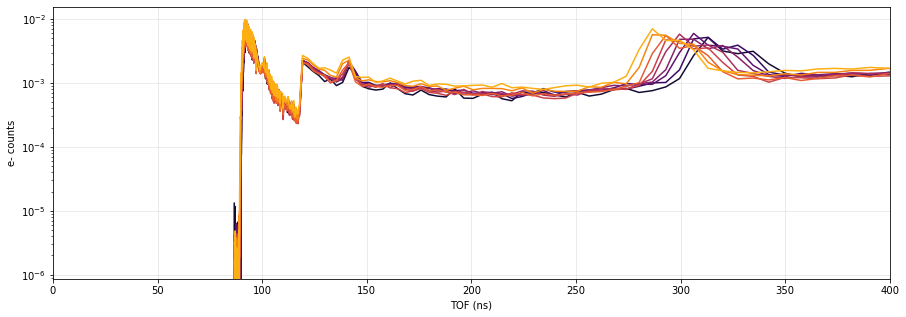

In [11]:
fig, ax = plt.subplots(figsize=(15,5))
ax.set_prop_cycle(plt.cycler('color', sns.color_palette('inferno', D[:10].shape[0])))
ax.semilogy(tof_e, D.mean(1)[1:10].T)
ax.set_xlabel('TOF (ns)')
ax.set_ylabel('e- counts')
ax.set_xlim(0, 400)

In [12]:
D.shape

(39, 5, 252)

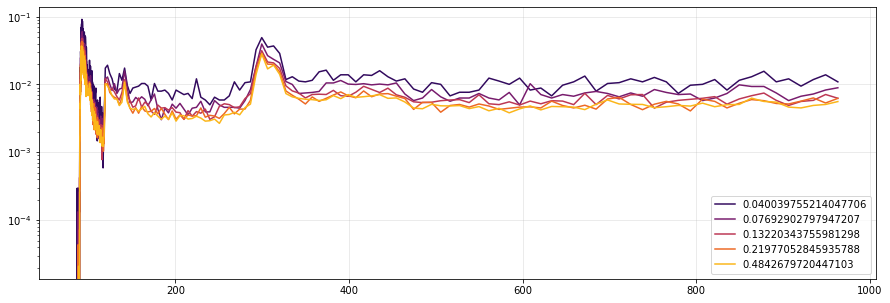

In [13]:
idx = 5
fig, ax = plt.subplots(figsize=(15,5))
ax.set_prop_cycle(plt.cycler('color', sns.color_palette('inferno', D.shape[1])))
ax.semilogy(tof_e, D[idx].T/G[idx])
# ax.plot(tof_e, D[idx].T)
ax.legend(G[idx])
# ax.set_xlim(50,200)

/tmp/ipykernel_2620396/3357664626.py:5: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  mesh = ax.pcolormesh(tof_e, tof_e, covdd, cmap = 'bwr', clim=(-2e-3, 2e-3))
/tmp/ipykernel_2620396/3357664626.py:6: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  plt.colorbar(mesh, ax=ax)
/tmp/ipykernel_2620396/3357664626.py:4: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  fig, ax = plt.subplots()


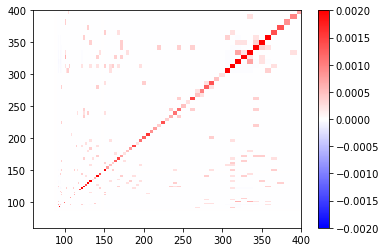

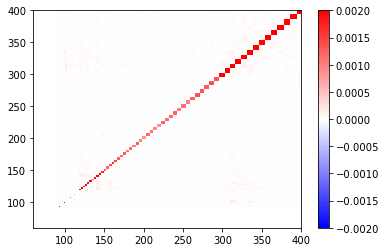

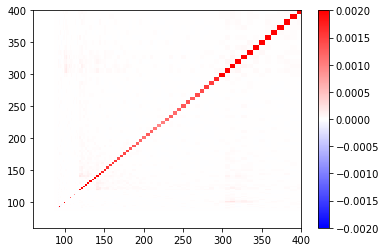

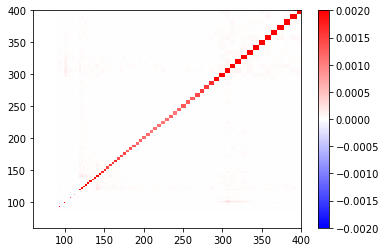

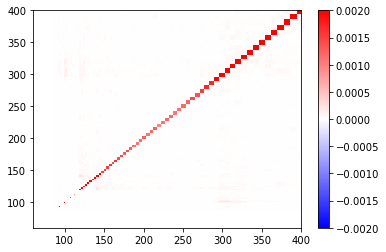

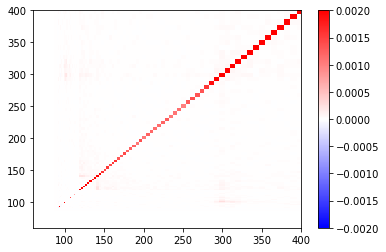

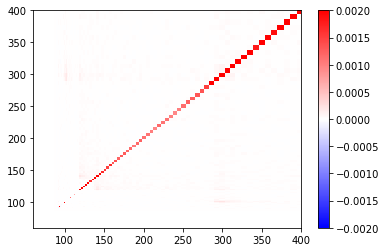

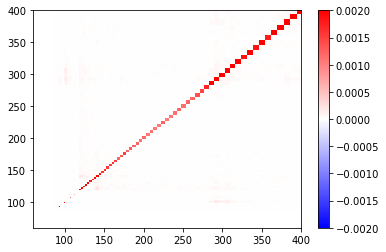

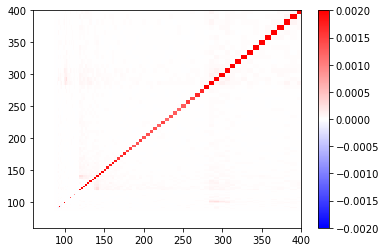

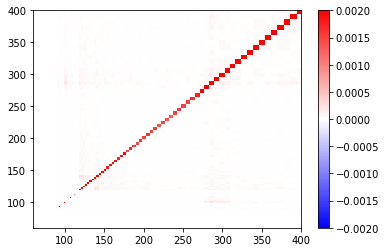

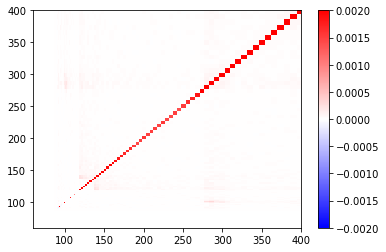

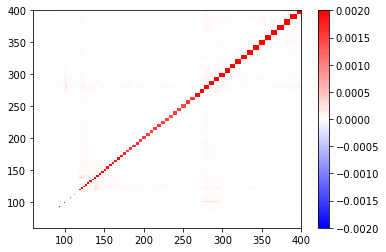

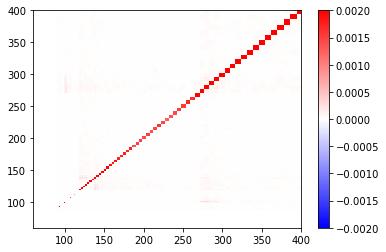

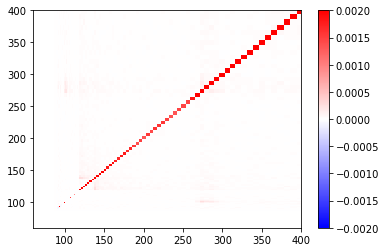

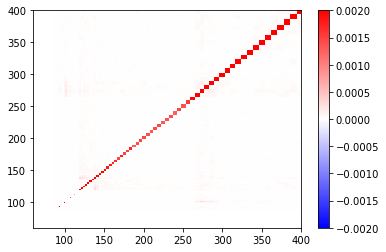

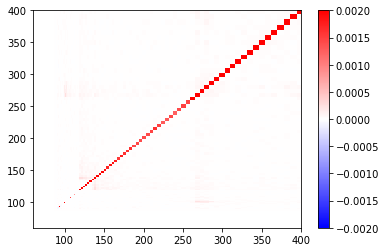

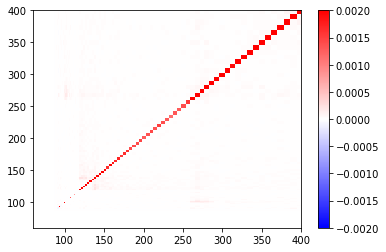

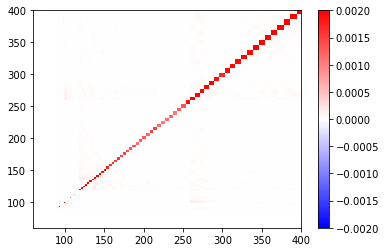

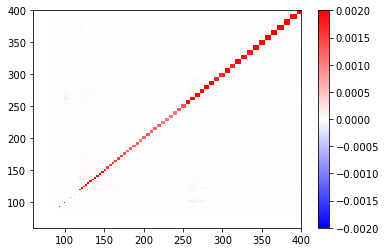

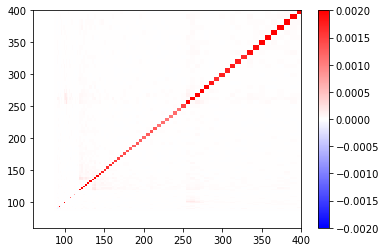

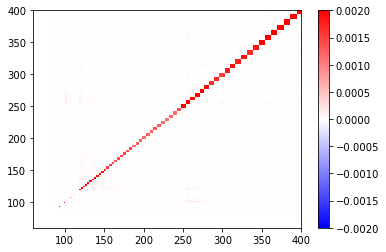

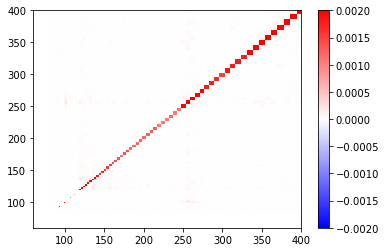

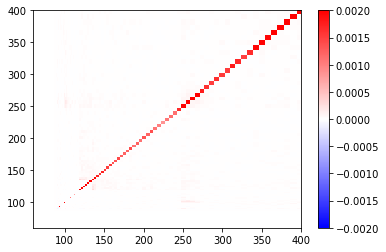

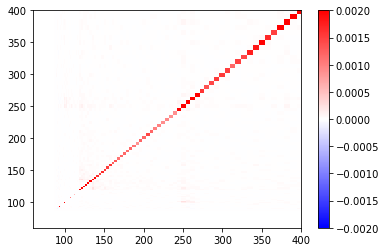

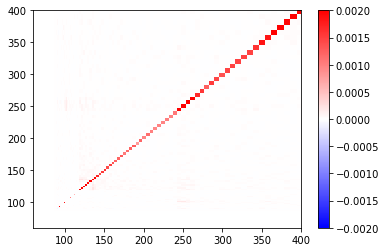

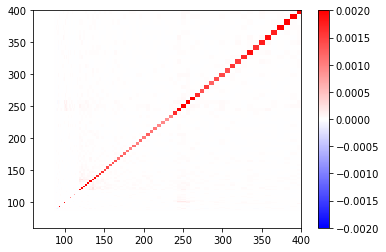

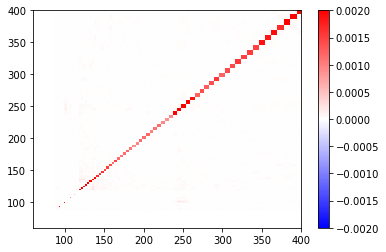

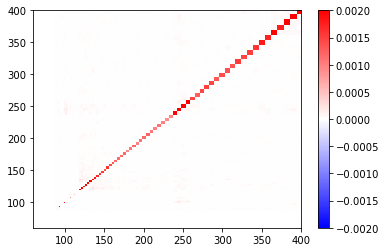

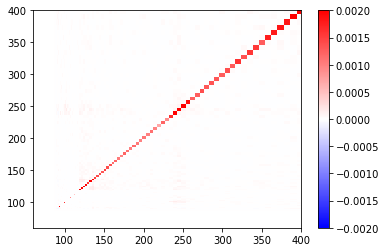

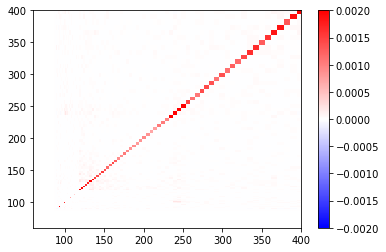

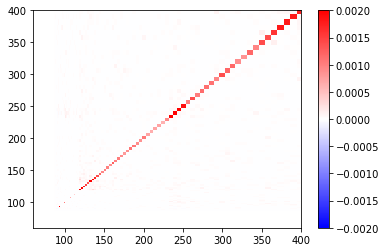

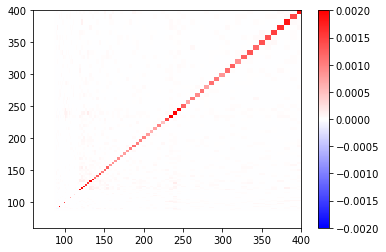

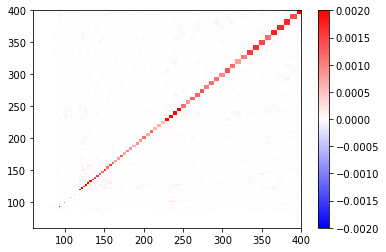

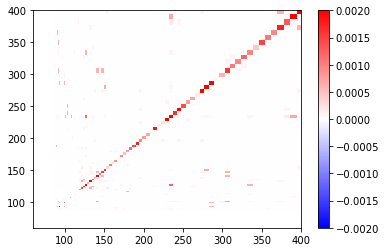

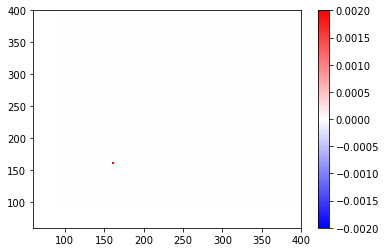

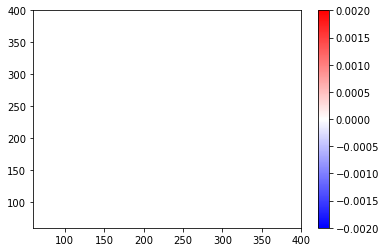

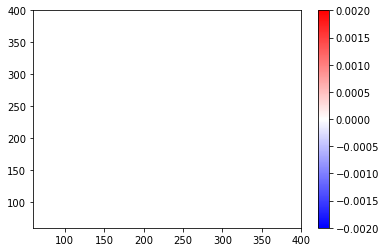

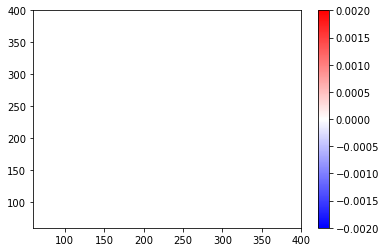

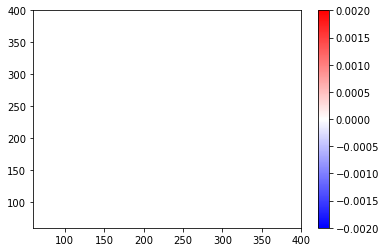

In [14]:
for d, dtd in zip(D[:,3:].mean(1), DtD[:,3:].mean(1)):
    covdd = dtd - np.outer(d,d)
    
    fig, ax = plt.subplots()
    mesh = ax.pcolormesh(tof_e, tof_e, covdd, cmap = 'bwr', clim=(-2e-3, 2e-3))
    plt.colorbar(mesh, ax=ax)
    ax.set_xlim(60, 400)
    ax.set_ylim(60, 400)

## Two-photon resonance: core → valence-hole excitation within one pulse

**Question.** Does a resonant channel open at high pulse energy in which one photon ionises the valence and a second
photon of the same pulse excites a core (C 1s) electron into the valence hole, the core-excited cation then decaying by
(resonant) Auger emission? Such a channel needs two photons, so its yield grows as G², and it is resonant: it appears at
the cation's core → valence-hole transition energy, roughly the C 1s binding energy minus the valence-hole energy
(≈ 291 − 11 ≈ 280 eV for a HOMO hole; deeper valence holes lie lower), i.e. inside this scan.

**Three views**, all from the aggregates (shots with a measured photon energy; cells with fewer than `MIN_SHOTS` shots
left out):
1. **Partial-yield XAS of fast electrons**: hits per shot in `HIGH_KE` against the measured photon energy, per µJ for
   each GMD bin and relative to a one-photon reference window `REF_KE`. In each photon-energy bin a weighted fit
   ⟨N⟩ = a₁⟨G⟩ + a₂⟨G²⟩ over the GMD bins (⟨G²⟩ = `GtG`); a two-photon resonance is a photon-energy-localised rise of
   a₂/a₁ and of the high/low-GMD ratio of the reference-normalised yield (GMD bins `HI_GMD_BINS` / `LO_GMD_BINS`
   pooled). The fit uses only photon-energy bins where every GMD bin has enough shots, so that its leverage is the same
   at all photon energies.
2. **Where in kinetic energy**: per-µJ spectra of the high GMD bins and their ratio to the low GMD bins, divided by that
   ratio's median over photon energy, so that only photon-energy-specific changes remain.
3. **Covariance**, partial on GMD within each cell, then averaged over the GMD bins `COV_GMD_BINS` (weighted by shots):
   electron pairs inside `HIGH_KE` (pairs closer than `DEAD_TIME_NS` in TOF left out: the detector dead time makes
   them negative), and the fast-electron count against the ion m/q spectrum.

**Caveat.** Every detected yield in these runs grows sublinearly with the GMD reading (the per-µJ yields fall about 2×
across the GMD bins at all photon energies; the argon run gives G^0.72), so a₂ comes out negative throughout and the
electron–electron covariance inside a window is negative (dead time). What matters is structure in photon energy; the
reference-normalised ratio removes the part common to all electrons.

In [15]:
# ---- Two-photon resonance: parameters ------------------------------------------
HIGH_KE = (210, 285)        # eV: fast electrons (valence photolines, resonant Auger); above the Ar L2,3-M2,3M2,3 Auger
REF_KE = (10, 40)           # eV: one-photon reference window (incl. the residual Ar 2p line)
MIN_SHOTS = 300             # cells (photon energy x GMD) with fewer shots are left out
HI_GMD_BINS = None          # GMD bins pooled as "high" / "low" for the ratios; None = top two / bottom two
LO_GMD_BINS = None
DEAD_TIME_NS = 1.0          # electron pairs closer than this in TOF are left out of the pair covariance
COV_GMD_BINS = None         # GMD bins averaged for the covariance maps; None = the top two
MAP_KE = (150, 285)         # eV, kinetic-energy range of the maps
MAP_REBIN = 6               # electron bins merged in the kinetic-energy ratio map
COMPARE_E = (280.0, 268.0)  # photon energies (eV) for the e-e maps: near the expected cation C 1s -> HOMO-hole
                            # resonance, and well below it

In [16]:
# Per cell (photon energy x GMD): hits per shot in the windows and the a1 / a2 fit per photon-energy bin
kc = calibration.ke_of_tof(0.5 * (tof_e_edges[1:] + tof_e_edges[:-1]))   # electron bin centres (TOF order)
w_hi = (kc >= HIGH_KE[0]) & (kc < HIGH_KE[1])
w_rf = (kc >= REF_KE[0]) & (kc < REF_KE[1])
ok = n >= MIN_SHOTS
n_g = n.shape[1]


def window_moments(w):
    # mean hits per shot in the window, its standard error, <N G>
    m = D[..., w].sum(-1)
    m2 = DtD[:, :, w][:, :, :, w].sum((-1, -2))
    se = np.sqrt(np.maximum(m2 - m ** 2, 0) / np.maximum(n, 1))
    return m, se, DtG[..., w].sum(-1)


N_hi, se_hi, NG_hi = window_moments(w_hi)
N_rf, se_rf, _ = window_moments(w_rf)
with np.errstate(invalid="ignore", divide="ignore"):
    y_uJ = np.where(ok, N_hi / G, np.nan)                       # fast electrons per µJ
    y_uJ_se = se_hi / G
    y_rel = np.where(ok, N_hi / N_rf, np.nan)                   # relative to the reference window
    y_rel_se = y_rel * np.sqrt((se_hi / N_hi) ** 2 + (se_rf / N_rf) ** 2)

a1, a2, r21, r21_se = (np.full(len(E), np.nan) for _ in range(4))
for e in range(len(E)):
    k = ok[e]
    if not k.all():                                             # same leverage at every photon energy
        continue
    X = np.c_[G[e, k], GtG[e, k]]
    wt = 1 / se_hi[e, k] ** 2
    cv = np.linalg.inv(X.T @ (X * wt[:, None]))
    a1[e], a2[e] = cv @ (X.T @ (wt * N_hi[e, k]))
    r21[e] = a2[e] / a1[e]
    r21_se[e] = abs(r21[e]) * np.sqrt(cv[1, 1] / a2[e] ** 2 + cv[0, 0] / a1[e] ** 2 - 2 * cv[0, 1] / (a1[e] * a2[e]))

gh = list(HI_GMD_BINS) if HI_GMD_BINS is not None else [n_g - 2, n_g - 1]
gl_ = list(LO_GMD_BINS) if LO_GMD_BINS is not None else [0, 1]


def pooled(x, gs):
    # shot-weighted mean over GMD bins gs per photon-energy bin (NaN unless all of them have enough shots)
    wts = n[:, gs].astype(float)
    shp = wts.shape + (1,) * (x.ndim - 2)
    out = (np.nan_to_num(x[:, gs]) * wts.reshape(shp)).sum(1) / wts.sum(1).reshape((-1,) + shp[2:])
    return np.where(ok[:, gs].all(1).reshape((-1,) + shp[2:]), out, np.nan)


def pooled_rel(gs):
    # reference-normalised fast-electron yield of the pooled GMD bins and its standard error
    nh, nr = pooled(N_hi, gs), pooled(N_rf, gs)
    sh = np.sqrt((n[:, gs] ** 2 * se_hi[:, gs] ** 2).sum(1)) / n[:, gs].sum(1)
    sr = np.sqrt((n[:, gs] ** 2 * se_rf[:, gs] ** 2).sum(1)) / n[:, gs].sum(1)
    r = nh / nr
    return r, r * np.sqrt((sh / nh) ** 2 + (sr / nr) ** 2)


r_hi, r_hi_se = pooled_rel(gh)
r_lo, r_lo_se = pooled_rel(gl_)
ratio_hl = r_hi / r_lo
ratio_hl_se = ratio_hl * np.sqrt((r_hi_se / r_hi) ** 2 + (r_lo_se / r_lo) ** 2)
print(f"HIGH_KE {HIGH_KE} eV: {w_hi.sum()} electron bins; REF_KE {REF_KE} eV: {w_rf.sum()} bins; "
      f"{ok.sum()} of {ok.size} cells with >= {MIN_SHOTS} shots")
print(f"{'E (eV)':>7s} {'a2/a1 (1/uJ)':>14s} {'hi/lo GMD (ref-norm.)':>22s}")
for e in np.flatnonzero(np.isfinite(r21) | np.isfinite(ratio_hl)):
    print(f"{E[e]:7.2f} {r21[e]:+8.3f} ± {r21_se[e]:.3f}   {ratio_hl[e]:8.3f} ± {ratio_hl_se[e]:.3f}")

HIGH_KE (210, 285) eV: 75 electron bins; REF_KE (10, 40) eV: 28 bins; 172 of 195 cells with >= 300 shots
 E (eV)   a2/a1 (1/uJ)  hi/lo GMD (ref-norm.)
 264.00   -0.501 ± 0.125      1.008 ± 0.175
 264.50   -0.417 ± 0.019      1.025 ± 0.047
 265.00   -0.558 ± 0.009      0.968 ± 0.023
 265.50   -0.572 ± 0.009      0.933 ± 0.020
 266.00   -0.596 ± 0.009      0.960 ± 0.020
 266.50   -0.533 ± 0.009      0.947 ± 0.020
 267.00   -0.560 ± 0.008      0.975 ± 0.021
 267.50   -0.482 ± 0.007      1.000 ± 0.023
 268.00   -0.465 ± 0.007      0.921 ± 0.020
 268.50   -0.463 ± 0.006      0.973 ± 0.021
 269.00   -0.468 ± 0.005      0.948 ± 0.020
 269.50   -0.468 ± 0.006      0.948 ± 0.020
 270.00   -0.477 ± 0.006      0.929 ± 0.020
 270.50   -0.507 ± 0.006      0.908 ± 0.019
 271.00   -0.531 ± 0.007      0.931 ± 0.019
 271.50   -0.538 ± 0.007      0.919 ± 0.019
 272.00   -0.527 ± 0.006      0.958 ± 0.020
 272.50   -0.573 ± 0.008      0.969 ± 0.019
 273.00   -0.579 ± 0.008      1.007 ± 0.021
 273.50   -0.

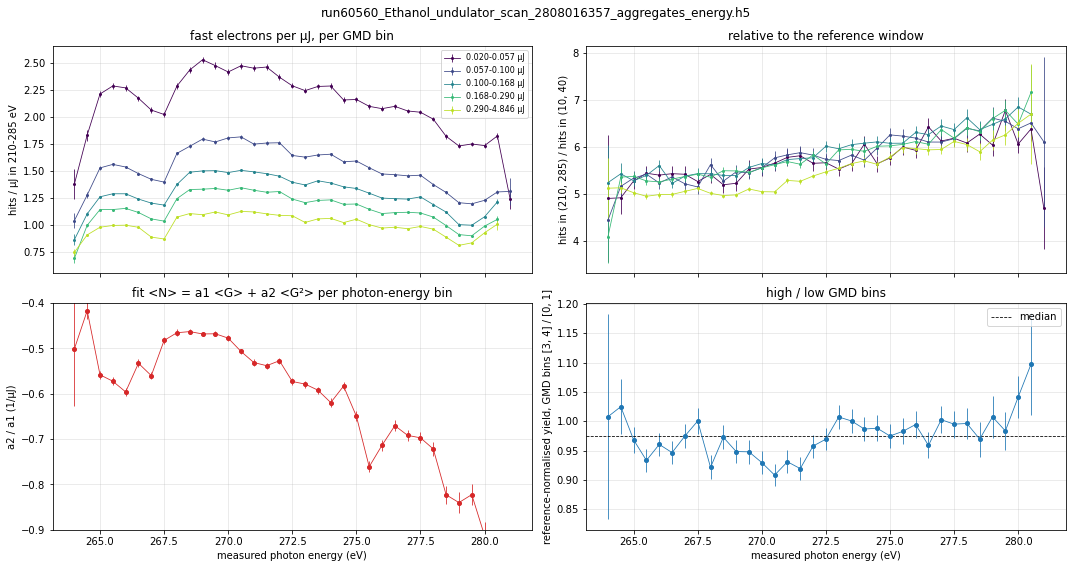

In [22]:
# Partial-yield XAS of the fast electrons
cols_g = plt.cm.viridis(np.linspace(0, 0.9, n_g))
gl = [f"{a:.3f}-{b:.3f} µJ" for a, b in zip(gmd_edges[:-1], gmd_edges[1:])]
fig, axs = plt.subplots(2, 2, figsize=(15, 8), sharex=True)
for g in range(n_g):
    axs[0, 0].errorbar(E, y_uJ[:, g], y_uJ_se[:, g], fmt=".-", color=cols_g[g], ms=4, lw=0.8, label=gl[g])
    axs[0, 1].errorbar(E, y_rel[:, g], y_rel_se[:, g], fmt=".-", color=cols_g[g], ms=4, lw=0.8, label=gl[g])
axs[0, 0].set(ylabel=f"hits / µJ in {HIGH_KE[0]}-{HIGH_KE[1]} eV", title="fast electrons per µJ, per GMD bin")
axs[0, 1].set(ylabel=f"hits in {HIGH_KE} / hits in {REF_KE}", title="relative to the reference window")
axs[0, 0].legend(fontsize=8)
axs[1, 0].errorbar(E, r21, r21_se, fmt="o-", ms=4, lw=0.8, color="C3")
axs[1, 0].set(ylabel="a2 / a1 (1/µJ)", title="fit <N> = a1 <G> + a2 <G²> per photon-energy bin")
axs[1, 1].errorbar(E, ratio_hl, ratio_hl_se, fmt="o-", ms=4, lw=0.8, color="C0")
axs[1, 1].axhline(np.nanmedian(ratio_hl), color="k", lw=0.8, ls="--", label="median")
axs[1, 1].set(ylabel=f"reference-normalised yield, GMD bins {gh} / {gl_}", title="high / low GMD bins")
axs[1, 1].legend()
for ax in axs[1]:
    ax.set_xlabel("measured photon energy (eV)")
fig.suptitle(agg_path.name)
fig.tight_layout()
axs[1,0].set_ylim(-.9, -.4)
plt.show()

/tmp/ipykernel_2620396/2405254541.py:18: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  m0 = axs[0].pcolormesh(map_edges, E_edges, s_hi, cmap="viridis",
/tmp/ipykernel_2620396/2405254541.py:20: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  fig.colorbar(m0, ax=axs[0], label="hits / µJ / eV")
/tmp/ipykernel_2620396/2405254541.py:23: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  m1 = axs[1].pcolormesh(map_edges, E_edges, r_hl_rel, cmap="RdBu_r", vmin=0.5, vmax=1.5)
/tmp/ipykernel_2620396/2405254541.py:24: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh(

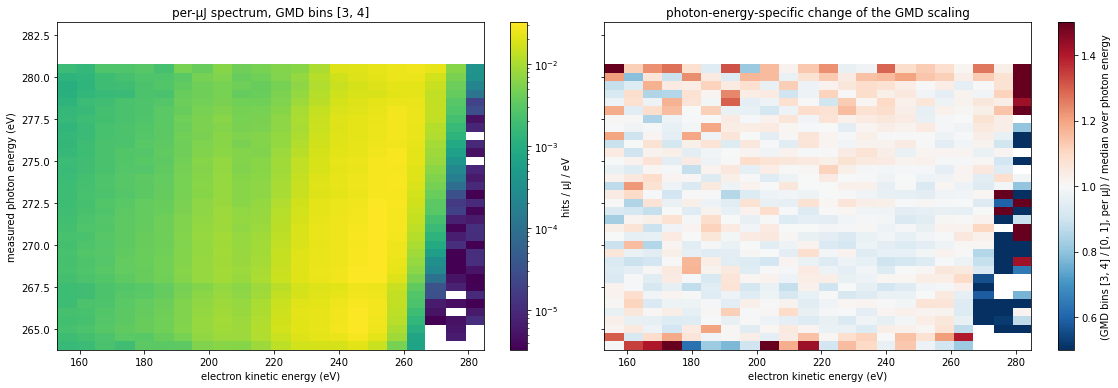

In [18]:
from matplotlib.colors import LogNorm

# Kinetic-energy resolved: per-µJ spectra at the highest GMD bin and the high/low ratio relative to its median over
# photon energy (1 = same GMD scaling as at the other photon energies)
sel = np.flatnonzero((kc >= MAP_KE[0]) & (kc < MAP_KE[1]))
sel = sel[: len(sel) // MAP_REBIN * MAP_REBIN]
grp = sel.reshape(-1, MAP_REBIN)
ke_e_all = calibration.ke_of_tof(tof_e_edges)
map_edges = np.r_[ke_e_all[grp[:, 0]], ke_e_all[grp[-1, -1] + 1]][::-1]        # rising energy
map_w = np.abs(np.diff(map_edges))
cnt = D[..., grp].sum(-1)[..., ::-1]                                           # hits per shot per merged bin, rising KE
with np.errstate(invalid="ignore", divide="ignore"):
    s_hi = pooled(cnt, gh) / pooled(G, gh)[:, None] / map_w                    # per µJ per eV, high GMD bins
    r_hl = (pooled(cnt, gh) / pooled(G, gh)[:, None]) / (pooled(cnt, gl_) / pooled(G, gl_)[:, None])
    r_hl_rel = r_hl / np.nanmedian(r_hl, axis=0)
fig, axs = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
pos = s_hi[np.isfinite(s_hi) & (s_hi > 0)]
m0 = axs[0].pcolormesh(map_edges, E_edges, s_hi, cmap="viridis",
                       norm=LogNorm(*np.percentile(pos, [1, 99.5])) if pos.size else None)
fig.colorbar(m0, ax=axs[0], label="hits / µJ / eV")
axs[0].set(xlabel="electron kinetic energy (eV)", ylabel="measured photon energy (eV)",
           title=f"per-µJ spectrum, GMD bins {gh}")
m1 = axs[1].pcolormesh(map_edges, E_edges, r_hl_rel, cmap="RdBu_r", vmin=0.5, vmax=1.5)
fig.colorbar(m1, ax=axs[1], label=f"(GMD bins {gh} / {gl_}, per µJ) / median over photon energy")
axs[1].set(xlabel="electron kinetic energy (eV)", title="photon-energy-specific change of the GMD scaling")
for ax in axs:
    ax.grid(False)
fig.tight_layout()
plt.show()

/tmp/ipykernel_2620396/2666239673.py:35: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  m = axs[1].pcolormesh(mq_e, E_edges, ei_map, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
/tmp/ipykernel_2620396/2666239673.py:36: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  fig.colorbar(m, ax=axs[1], label="pcov(fast electrons, ions) per shot per u/e")


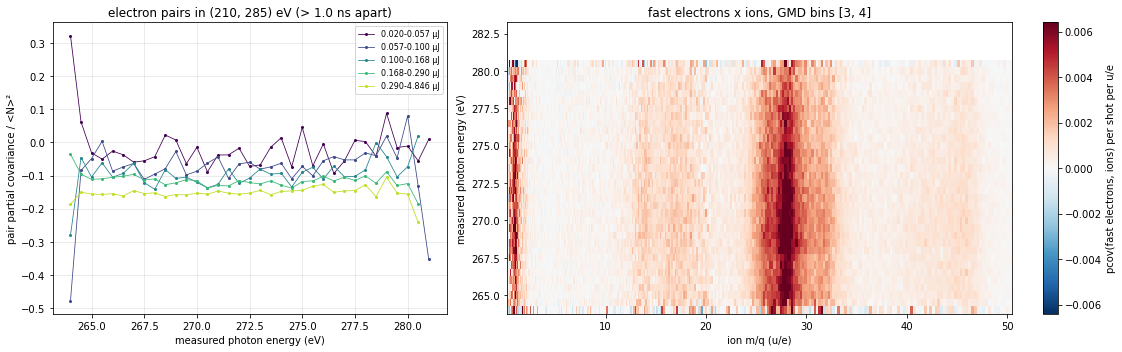

In [19]:
# Partial covariance on GMD within each cell, averaged over the GMD bins COV_GMD_BINS (weighted by shots)
gsel = list(COV_GMD_BINS) if COV_GMD_BINS is not None else [n_g - 2, n_g - 1]
ih = np.flatnonzero(w_hi)
vG = GtG - G ** 2
Dw, DGw = D[..., ih], DtG[..., ih]
cDG = DGw - Dw * G[..., None]
pcov_ee = (DtD[:, :, ih][:, :, :, ih] - Dw[..., :, None] * Dw[..., None, :]
           - cDG[..., :, None] * cDG[..., None, :] / vG[..., None, None])
t_hi = 0.5 * (tof_e_edges[ih] + tof_e_edges[ih + 1])                       # ns
far = np.abs(t_hi[:, None] - t_hi[None, :]) > DEAD_TIME_NS
with np.errstate(invalid="ignore", divide="ignore"):
    pair_rel = np.where(ok, (pcov_ee * far).sum((-1, -2)) / N_hi ** 2, np.nan)   # pairs per shot / <N>^2
cNG = NG_hi - N_hi * G
cCG = CtG - C * G[..., None]
pcov_ei = DtC[:, :, ih, :].sum(2) - N_hi[..., None] * C - cNG[..., None] * cCG / vG[..., None]


def gavg(x):
    # shot-weighted mean over the GMD bins gsel (cells below MIN_SHOTS left out), per photon-energy bin
    wts = np.where(ok[:, gsel], n[:, gsel], 0).astype(float)
    shp = wts.shape + (1,) * (x.ndim - 2)
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.nansum(np.nan_to_num(x[:, gsel]) * wts.reshape(shp), axis=1) / wts.sum(1).reshape((-1,) + shp[2:])


mq_e = calibration.mq_of_tof(tof_i_edges)
ei_map = gavg(pcov_ei) / np.diff(mq_e)                                       # per shot per u/e
fig, axs = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1.6]})
for g in range(n_g):
    axs[0].plot(E, pair_rel[:, g], ".-", color=cols_g[g], ms=4, lw=0.8, label=gl[g])
axs[0].set(xlabel="measured photon energy (eV)", ylabel="pair partial covariance / <N>²",
           title=f"electron pairs in {HIGH_KE} eV (> {DEAD_TIME_NS} ns apart)")
axs[0].legend(fontsize=8)
vmax = np.nanpercentile(np.abs(ei_map), 99)
m = axs[1].pcolormesh(mq_e, E_edges, ei_map, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
fig.colorbar(m, ax=axs[1], label="pcov(fast electrons, ions) per shot per u/e")
axs[1].set(xlabel="ion m/q (u/e)", ylabel="measured photon energy (eV)",
           title=f"fast electrons x ions, GMD bins {gsel}")
axs[1].grid(False)
fig.tight_layout()
plt.show()

/tmp/ipykernel_2620396/2173687095.py:15: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  mesh = ax.pcolormesh(edges_hi, edges_hi, mp, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
/tmp/ipykernel_2620396/2173687095.py:19: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  fig.colorbar(mesh, ax=axs, label="partial covariance per shot per eV²", shrink=0.8)


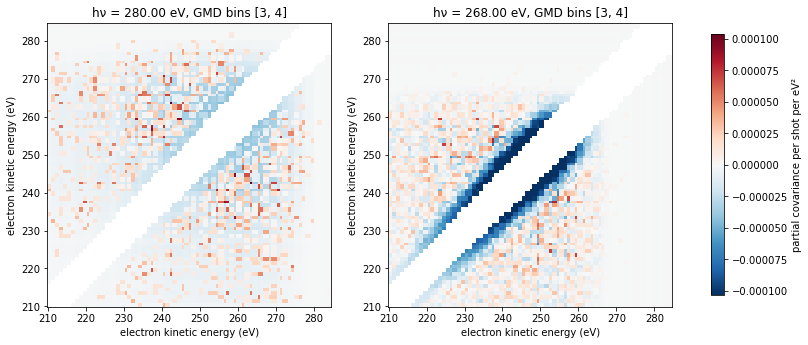

In [20]:
# Electron-electron partial covariance maps (per eV^2) inside HIGH_KE at two photon energies
ee = gavg(pcov_ee)                                                           # (nE, n_hi, n_hi), TOF order
o = np.argsort(kc[ih])
edges_hi = np.sort(calibration.ke_of_tof(tof_e_edges[ih[0]:ih[-1] + 2]))
w_ee = np.diff(edges_hi)
maps = []
for Ec in COMPARE_E:
    e = int(np.argmin(np.abs(E - Ec)))
    mp = ee[e][np.ix_(o, o)] / np.outer(w_ee, w_ee)
    mp[~far[np.ix_(o, o)]] = np.nan
    maps.append((E[e], mp))
vmax = np.nanpercentile(np.abs(np.concatenate([m.ravel() for _, m in maps])), 99)
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
for ax, (Ec, mp) in zip(axs, maps):
    mesh = ax.pcolormesh(edges_hi, edges_hi, mp, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set(xlabel="electron kinetic energy (eV)", ylabel="electron kinetic energy (eV)", aspect="equal",
           title=f"hν = {Ec:.2f} eV, GMD bins {gsel}")
    ax.grid(False)
fig.colorbar(mesh, ax=axs, label="partial covariance per shot per eV²", shrink=0.8)
plt.show()